# Titanic Survival Analysis
**Who survived the Titanic disaster, and which factors were associated with survival?**

## 1. Project Overview
This project explores the Titanic passenger dataset (891 passengers with a recorded survival outcome). Rather than only counting survivors, it builds up a set of questions, from data quality through to a multivariate view:

1. **Data quality:** what is missing, and is the missingness random?
2. **Who survived overall**, and how did **sex** and **passenger class** matter, alone and together?
3. **Age:** were children treated differently, and does the missing age data bias the picture?
4. **Fare and class:** does fare add information beyond class?
5. **Family:** is travelling alone, or in a large family, related to survival?
6. **Port of embarkation:** is the apparent port effect real, or a class effect in disguise?
7. **Which factors still matter when considered together?** (logistic regression on odds ratios)

**Skills demonstrated:** missing-value analysis, group-wise imputation, feature engineering (title, family size), `groupby`/pivot analysis, confidence intervals, chi-square and Mann-Whitney tests, confounding checks, logistic regression.

> **Caveat:** this is observational data on a single event. Patterns are *associations*; they show who survived, not why.

## 2. Setup

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.options.display.float_format = "{:,.2f}".format
PALETTE = {0: "#c0504d", 1: "#4f81bd"}          # 0 = did not survive, 1 = survived
SURV_LABELS = {0: "Did not survive", 1: "Survived"}

def survival_ci(successes, n):
    """95% Wilson confidence interval for a proportion."""
    lo, hi = stats.binomtest(int(successes), int(n)).proportion_ci(confidence_level=0.95, method="wilson")
    return lo, hi

def survival_table(df, by):
    """Survival rate, group size and 95% CI for one or more grouping columns."""
    g = df.groupby(by, observed=True)["Survived"].agg(survivors="sum", passengers="count")
    g["survival_rate"] = g["survivors"] / g["passengers"]
    ci = [survival_ci(s, n) for s, n in zip(g["survivors"], g["passengers"])]
    g["ci_low"], g["ci_high"] = [c[0] for c in ci], [c[1] for c in ci]
    return g

## 3. Dataset Understanding
The data is the Kaggle Titanic *train* file (the original coursework read a Google-Sheets copy of it). The loader tries a local copy first and then a public mirror of the same file.

| Column | Meaning |
|---|---|
| `PassengerId` | Row identifier |
| `Survived` | Target: 1 = survived, 0 = did not |
| `Pclass` | Ticket class (1 = upper, 2 = middle, 3 = lower) |
| `Name`, `Sex`, `Age` | Passenger details (age in years, fractional for infants) |
| `SibSp` | Number of siblings / spouses aboard |
| `Parch` | Number of parents / children aboard |
| `Ticket`, `Fare`, `Cabin` | Ticket number, fare paid (pounds, as recorded), cabin |
| `Embarked` | Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton) |

In [2]:
SOURCES = [
    "train - train.csv", "train.csv", "titanic.csv",
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv",
]
def load_first_available(sources):
    errors = []
    for src in sources:
        try:
            if not src.startswith("http") and not Path(src).exists():
                continue
            return pd.read_csv(src), src
        except Exception as exc:
            errors.append(f"{src}: {exc}")
    raise FileNotFoundError("Could not load the Titanic file.\n" + "\n".join(errors))

raw, source_used = load_first_available(SOURCES)
print("Loaded from:", source_used, "| shape:", raw.shape)
raw.head()

Loaded from: titanic.csv | shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


## 4. Data Quality Assessment

In [3]:
quality = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                        "missing_%": raw.isna().mean() * 100, "unique": raw.nunique()})
display(quality)
print("Duplicate rows:", raw.duplicated().sum(), "| PassengerId unique:", raw["PassengerId"].is_unique,
      "| Duplicate names:", raw["Name"].duplicated().sum())
print("Survived values:", sorted(raw["Survived"].unique()), "| Pclass values:", sorted(raw["Pclass"].unique()),
      "| Sex values:", sorted(raw["Sex"].unique()), "| Embarked values:", raw["Embarked"].dropna().unique().tolist())

,dtype,missing,missing_%,unique
PassengerId,int64,0,0.00,891
Survived,int64,0,0.00,2
Pclass,int64,0,0.00,3
Name,str,0,0.00,891
Sex,str,0,0.00,2
Age,float64,177,19.87,88
SibSp,int64,0,0.00,7
Parch,int64,0,0.00,7
Ticket,str,0,0.00,681
Fare,float64,0,0.00,248


Duplicate rows: 0 | PassengerId unique: True | Duplicate names: 0
Survived values: [np.int64(0), np.int64(1)] | Pclass values: [np.int64(1), np.int64(2), np.int64(3)] | Sex values: ['female', 'male'] | Embarked values: ['S', 'C', 'Q']


In [4]:
# Suspicious values: zero fares, extreme fares, and passengers sharing a ticket
print("Passengers with Fare = 0:", (raw["Fare"] == 0).sum())
display(raw.loc[raw["Fare"] == 0, ["Name", "Pclass", "Sex", "Embarked", "Survived"]].head(15))

q1, q3 = raw["Fare"].quantile([0.25, 0.75]); fence = q3 + 1.5 * (q3 - q1)
print(f"\nFare upper IQR fence: {fence:.1f} | passengers above it: {(raw['Fare'] > fence).sum()} "
      f"| maximum fare: {raw['Fare'].max():.1f}")
print("Passengers paying more than 500:", (raw["Fare"] > 500).sum())

ticket_sizes = raw.groupby("Ticket")["Fare"].agg(n="size", distinct_fares="nunique")
print(f"\nTickets shared by 2+ passengers: {(ticket_sizes['n'] > 1).sum()} "
      f"| of these, tickets with differing fares: {((ticket_sizes['n'] > 1) & (ticket_sizes['distinct_fares'] > 1)).sum()}")

Passengers with Fare = 0: 15


,Name,Pclass,Sex,Embarked,Survived
179,"Leonard, Mr. Lionel",3,male,S,0
263,"Harrison, Mr. William",1,male,S,0
271,"Tornquist, Mr. William Henry",3,male,S,1
277,"Parkes, Mr. Francis ""Frank""",2,male,S,0
302,"Johnson, Mr. William Cahoone Jr",3,male,S,0
413,"Cunningham, Mr. Alfred Fleming",2,male,S,0
466,"Campbell, Mr. William",2,male,S,0
481,"Frost, Mr. Anthony Wood ""Archie""",2,male,S,0
597,"Johnson, Mr. Alfred",3,male,S,0
633,"Parr, Mr. William Henry Marsh",1,male,S,0



Fare upper IQR fence: 65.6 | passengers above it: 116 | maximum fare: 512.3
Passengers paying more than 500: 3

Tickets shared by 2+ passengers: 134 | of these, tickets with differing fares: 1


**What the data shows**
- 891 passengers, no duplicate rows or names, and `PassengerId` is unique. Categorical values are clean (only `male`/`female`; ports `S`, `C`, `Q`).
- Three columns have gaps: **`Cabin` 77.1%** missing, **`Age` 19.9%** (177 rows) and **`Embarked` 0.2%** (2 rows).
- **15 passengers have a fare of 0** (all men, all boarded at Southampton, 1 survived). The data cannot say whether these are errors or genuine special tickets, so they are flagged rather than removed.
- Fares are strongly right-skewed: 116 passengers exceed the IQR upper fence (65.6) and 3 paid more than 500. These are real first-class fares, not errors, so they are kept.
- 134 tickets are shared by two or more passengers, and on all but one of them every holder shows the same fare. So the `Fare` column repeats the ticket price for each holder, which is why a per-person fare is derived later.

### Is the missing `Age` random?
`Age` has the most consequential gaps, so before deciding how to handle them I check whether missingness is related to class or to survival. If it is, dropping those rows would bias the results. This also answers the original brief's question about average age and missing ages per class.

In [5]:
age_by_class = raw.groupby("Pclass")["Age"].agg(mean_age="mean", median_age="median",
                                                 missing_ages=lambda s: s.isna().sum(), passengers="size")
age_by_class["missing_%"] = age_by_class["missing_ages"] / age_by_class["passengers"] * 100
display(age_by_class)

miss = raw.assign(age_missing=raw["Age"].isna())
print("Survival rate by whether age is recorded:")
display(survival_table(miss, "age_missing"))
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(miss["Pclass"], miss["age_missing"]))
print(f"Chi-square, age missingness vs class: chi2 = {chi2:.1f}, p = {p:.2g}")

,mean_age,median_age,missing_ages,passengers,missing_%
Pclass,,,,,
1,38.23,37.00,30,216,13.89
2,29.88,29.00,11,184,5.98
3,25.14,24.00,136,491,27.70


Survival rate by whether age is recorded:


,survivors,passengers,survival_rate,ci_low,ci_high
age_missing,,,,,
False,290,714,0.41,0.37,0.44
True,52,177,0.29,0.23,0.36


Chi-square, age missingness vs class: chi2 = 46.1, p = 9.9e-11


**What the data shows:** missing ages are **not random**. They affect 27.7% of third-class passengers, versus 13.9% in first class and 6.0% in second class (chi-square p ≈ 1e-10). Passengers without a recorded age also survived less often (29% vs 41%). Average recorded age falls with class: 38.2 (1st), 29.9 (2nd), 25.1 (3rd).

**Interpretation:** simply dropping rows with missing age would under-represent third-class passengers and slightly overstate survival. Note also that the class averages themselves are computed on recorded ages only; the true third-class mean may differ. This is why age-specific charts state that they use recorded ages, and why a class/title-aware imputation is used where a full column is needed.

## 5. Data Cleaning & Preparation
Decisions, in order:

1. **`Embarked` (2 missing):** filled with the **most common port within the passenger's class** (group-wise mode via `groupby().transform`). The original notebook's `fillna(df["Embarked"].mode())` only fills row 0, because `mode()` returns a Series and pandas aligns it on the index; that has been corrected.
2. **`Age` (177 missing):** the raw column is kept. A separate `AgeFilled` column uses the **median age of the passenger's title group** (Master, Miss, Mr, Mrs, ...) within class. Title is a strong age signal (e.g. *Master* = boy) and this preserves the age structure better than one global median. Age-specific charts use recorded ages only; `AgeFilled` is used where a complete column is required (modelling).
3. **`Cabin` (77% missing):** not imputed. Replaced by two derived features: `HasCabin` and `Deck` (first letter).
4. **Feature engineering:** `Title`, `FamilySize` (SibSp + Parch + 1), `IsAlone`, `TicketGroupSize` and `FarePerPerson` (fare divided by ticket group size, because fares are repeated across passengers who share a ticket).
5. **Zero fares** are kept but flagged: they are few and may be genuine (e.g. staff or special tickets), which the data cannot confirm.

In [6]:
df = raw.copy()

# 1. Embarked: mode within passenger class
df["Embarked"] = df.groupby("Pclass")["Embarked"].transform(lambda s: s.fillna(s.mode().iloc[0]))
print("Embarked missing after imputation:", df["Embarked"].isna().sum())
print(df.groupby("Pclass")["Embarked"].value_counts(ascending=True).unstack().fillna(0).astype(int))

# 2. Title (from Name) -> grouped
# Title = first word after the comma; robust to names written with or without a period after the title
df["Title"] = df["Name"].str.extract(r",\s*(the Countess|[A-Za-z]+)", expand=False).str.strip()
title_map = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs", "Lady": "Rare", "the Countess": "Rare", "Sir": "Rare"}
df["Title"] = df["Title"].replace(title_map)
df.loc[~df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Title"] = "Rare"
print("\nTitle counts:"); print(df["Title"].value_counts().to_string())
assert df["Title"].isna().sum() == 0

Embarked missing after imputation: 0
Embarked   C   Q    S
Pclass               
1         85   2  129
2         17   3  164
3         66  72  353

Title counts:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23


In [7]:
# 3. Age: median by Title within class (recorded ages only)
df["AgeFilled"] = df["Age"].fillna(df.groupby(["Title", "Pclass"])["Age"].transform("median"))
df["AgeFilled"] = df["AgeFilled"].fillna(df.groupby("Title")["Age"].transform("median"))   # any empty Title x Pclass cell
print("Age missing after imputation:", df["AgeFilled"].isna().sum())

# 4. Family, cabin and ticket features
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["HasCabin"] = df["Cabin"].notna().astype(int)
df["Deck"] = df["Cabin"].str[0]
df["TicketGroupSize"] = df.groupby("Ticket")["PassengerId"].transform("size")
df["FarePerPerson"] = df["Fare"] / df["TicketGroupSize"]
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
                        labels=["Child (0-12)", "Teen (13-18)", "Adult (19-35)", "Middle-aged (36-60)", "Senior (61+)"])
df["Sex"] = df["Sex"].str.title()

df[["Name", "Title", "Age", "AgeFilled", "FamilySize", "IsAlone", "HasCabin", "Deck", "TicketGroupSize", "FarePerPerson"]].head()

Age missing after imputation: 0


,Name,Title,Age,AgeFilled,FamilySize,IsAlone,HasCabin,Deck,TicketGroupSize,FarePerPerson
0,"Braund, Mr. Owen Harris",Mr,22.00,22.00,2,0,0,NaN,1,7.25
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,38.00,38.00,2,0,1,C,1,71.28
2,"Heikkinen, Miss Laina",Miss,26.00,26.00,1,1,0,NaN,1,7.92
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,35.00,35.00,2,0,1,C,2,26.55
4,"Allen, Mr. William Henry",Mr,35.00,35.00,1,1,0,NaN,1,8.05


## 6. Exploratory Analysis
### Q1. What was the overall survival rate, and who were the passengers?

Overall survival: 342 of 891 passengers = 38.4% (95% CI 35.2% to 41.6%)


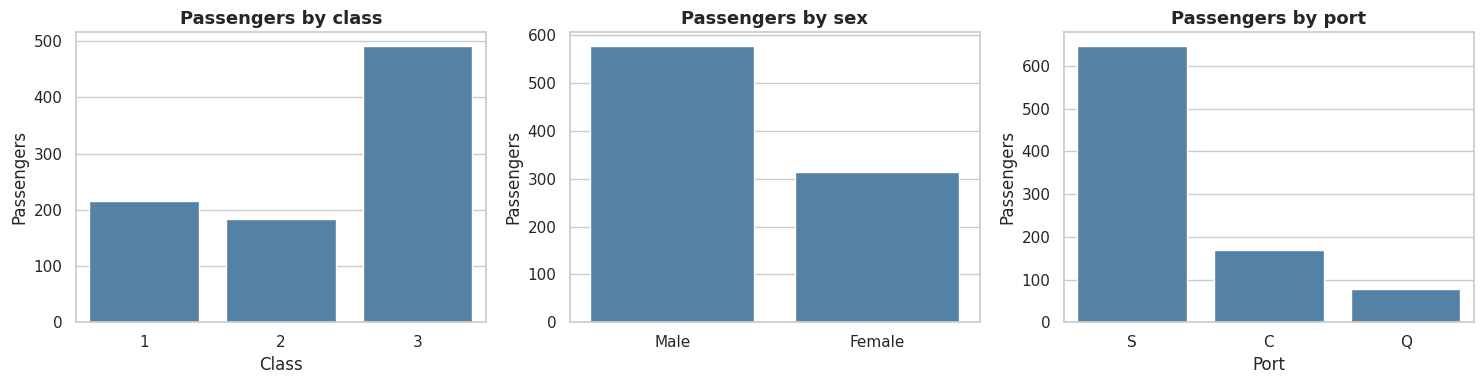

In [8]:
overall = df["Survived"].mean()
lo, hi = survival_ci(df["Survived"].sum(), len(df))
print(f"Overall survival: {df['Survived'].sum()} of {len(df)} passengers = {overall:.1%} (95% CI {lo:.1%} to {hi:.1%})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="Pclass", color="steelblue", ax=axes[0]); axes[0].set(title="Passengers by class", xlabel="Class", ylabel="Passengers")
sns.countplot(data=df, x="Sex", color="steelblue", ax=axes[1]); axes[1].set(title="Passengers by sex", xlabel="", ylabel="Passengers")
sns.countplot(data=df, x="Embarked", color="steelblue", ax=axes[2], order=["S", "C", "Q"]); axes[2].set(title="Passengers by port", xlabel="Port", ylabel="Passengers")
plt.tight_layout(); plt.show()

### Q2. How did sex and passenger class relate to survival?
Rates are shown with 95% confidence intervals, because some groups are small.

,survivors,passengers,survival_rate,ci_low,ci_high
Sex,,,,,
Female,233,314,0.74,0.69,0.79
Male,109,577,0.19,0.16,0.22


,survivors,passengers,survival_rate,ci_low,ci_high
Pclass,,,,,
1,136,216,0.63,0.56,0.69
2,87,184,0.47,0.40,0.55
3,119,491,0.24,0.21,0.28


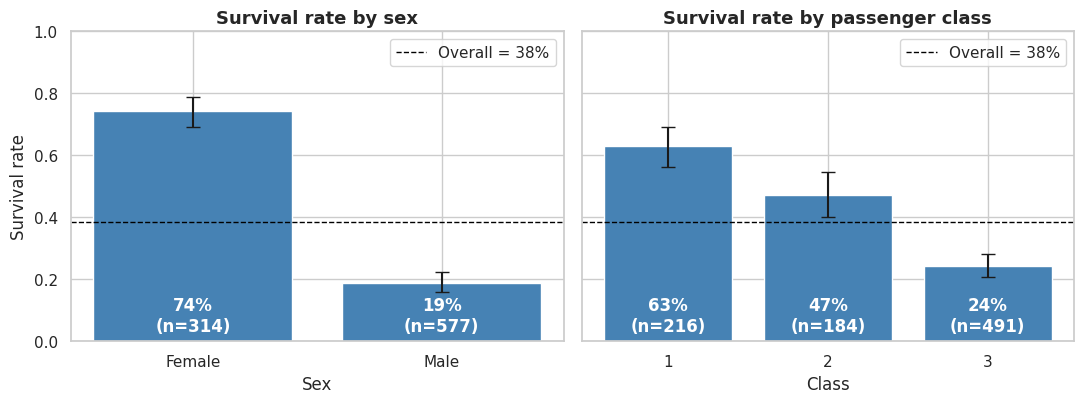

Chi-square, survival vs sex: chi2 = 260.7, p = 1.2e-58
Chi-square, survival vs class: chi2 = 102.9, p = 4.5e-23


In [9]:
sex_t = survival_table(df, "Sex"); cls_t = survival_table(df, "Pclass")
display(sex_t.round(3)); display(cls_t.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, t, title, xl in [(axes[0], sex_t, "Survival rate by sex", "Sex"), (axes[1], cls_t, "Survival rate by passenger class", "Class")]:
    x = t.index.astype(str)
    ax.bar(x, t["survival_rate"], color="steelblue", yerr=[t["survival_rate"] - t["ci_low"], t["ci_high"] - t["survival_rate"]], capsize=5)
    ax.axhline(overall, color="black", ls="--", lw=1, label=f"Overall = {overall:.0%}")
    for i, (r, n) in enumerate(zip(t["survival_rate"], t["passengers"])):
        ax.text(i, 0.02, f"{r:.0%}\n(n={n})", ha="center", va="bottom", color="white", fontweight="bold")
    ax.set(title=title, xlabel=xl, ylim=(0, 1)); ax.legend(loc="upper right")
axes[0].set_ylabel("Survival rate")
plt.tight_layout(); plt.show()

for name, var in [("sex", "Sex"), ("class", "Pclass")]:
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df[var], df["Survived"]))
    print(f"Chi-square, survival vs {name}: chi2 = {chi2:.1f}, p = {p:.2g}")

**What the data shows:** 342 of 891 passengers survived (**38.4%**). **Women survived at 74.2%** (233 of 314) versus **18.9% for men** (109 of 577). By class: **63.0%** (1st), **47.3%** (2nd), **24.2%** (3rd). The confidence intervals for the three classes do not overlap, and both associations are highly significant (chi-square p < 1e-20).

**Interpretation:** sex was the strongest single split in the data, class the second. Because men outnumbered women almost two to one and were over-represented in third class, the overall rate is pulled down; the next chart shows how the two factors combine.

### Q3. How do sex and class combine?
A heatmap of the survival rate in each Sex × Class cell shows whether one factor overrides the other.

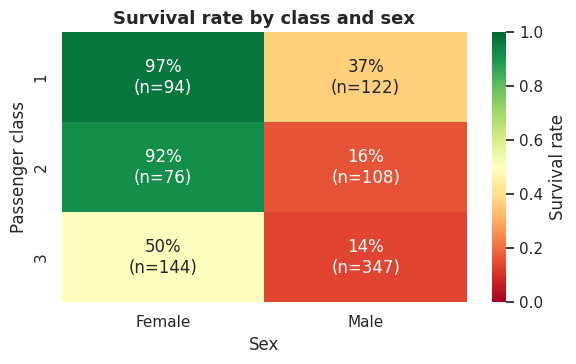

survivors  passengers  survival_rate  ci_low  ci_high
Pclass Sex                                                          
1      Female         91          94           0.97    0.91     0.99
       Male           45         122           0.37    0.29     0.46
2      Female         70          76           0.92    0.84     0.96
       Male           17         108           0.16    0.10     0.24
3      Female         72         144           0.50    0.42     0.58
       Male           47         347           0.14    0.10     0.17

In [10]:
sc = survival_table(df, ["Pclass", "Sex"])
heat = sc["survival_rate"].unstack("Sex")
counts = sc["passengers"].unstack("Sex")
annot = heat.map(lambda v: f"{v:.0%}") + "\n(n=" + counts.astype(str) + ")"

fig, ax = plt.subplots(figsize=(6, 3.8))
sns.heatmap(heat, annot=annot, fmt="", cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "Survival rate"}, ax=ax)
ax.set(title="Survival rate by class and sex", xlabel="Sex", ylabel="Passenger class")
plt.tight_layout(); plt.show()
sc.round(3)

**What the data shows**

| | Female | Male |
|---|---|---|
| 1st class | 97% (n=94) | 37% (n=122) |
| 2nd class | 92% (n=76) | 16% (n=108) |
| 3rd class | 50% (n=144) | 14% (n=347) |

- Among **women**, class made a large difference: nearly all first- and second-class women survived, but only half of third-class women.
- Among **men**, only first class stood out (37%); second- and third-class men were similar (16% and 14%).
- Third-class women (50%) survived at a higher rate than first-class men (37%).

**Interpretation:** the effects interact: the class gap is much bigger for women than for men, and the sex gap is smallest in third class. Any single-factor summary hides this, which is why the later regression should be read as average effects.

## 7. Age
### Q4. Did survival differ by age, and were children treated differently?

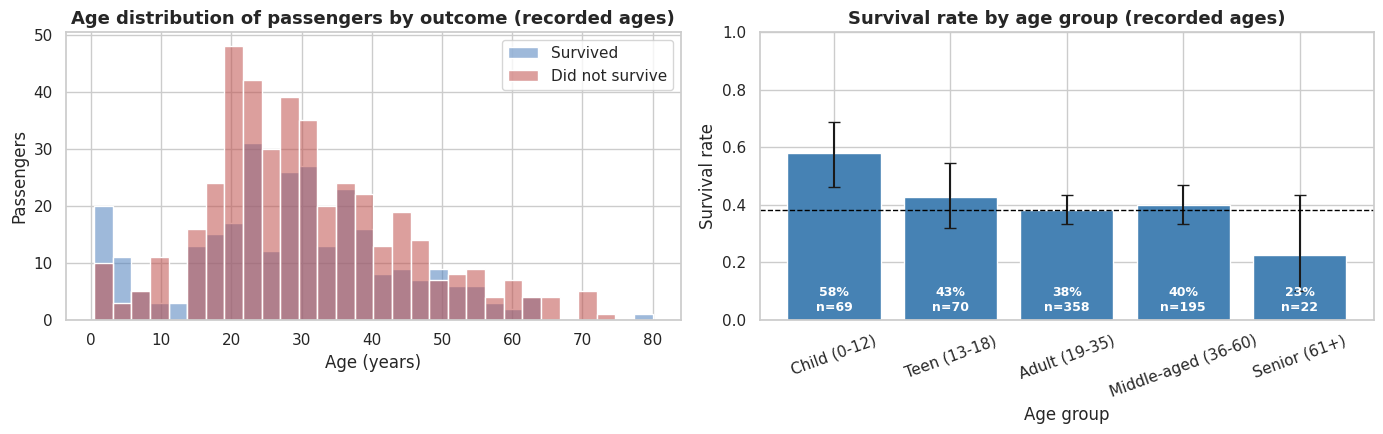

Median age - survivors: 28, non-survivors: 28 | Mann-Whitney p = 0.160


In [11]:
recorded = df.dropna(subset=["Age"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=recorded, x="Age", hue="Survived", bins=30, multiple="layer", stat="count", palette=PALETTE, alpha=0.55, ax=axes[0])
axes[0].set(title="Age distribution of passengers by outcome (recorded ages)", xlabel="Age (years)", ylabel="Passengers")
axes[0].legend(title="", labels=[SURV_LABELS[1], SURV_LABELS[0]])

age_t = survival_table(recorded, "AgeGroup")
axes[1].bar(age_t.index.astype(str), age_t["survival_rate"], color="steelblue",
            yerr=[age_t["survival_rate"] - age_t["ci_low"], age_t["ci_high"] - age_t["survival_rate"]], capsize=4)
axes[1].axhline(overall, color="black", ls="--", lw=1)
for i, (r, n) in enumerate(zip(age_t["survival_rate"], age_t["passengers"])):
    axes[1].text(i, 0.02, f"{r:.0%}\nn={n}", ha="center", va="bottom", color="white", fontweight="bold", fontsize=9)
axes[1].set(title="Survival rate by age group (recorded ages)", xlabel="Age group", ylabel="Survival rate", ylim=(0, 1))
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

u = stats.mannwhitneyu(recorded.loc[recorded["Survived"] == 1, "Age"], recorded.loc[recorded["Survived"] == 0, "Age"])
print(f"Median age - survivors: {recorded.loc[recorded['Survived']==1,'Age'].median():.0f}, non-survivors: {recorded.loc[recorded['Survived']==0,'Age'].median():.0f} "
      f"| Mann-Whitney p = {u.pvalue:.3f}")

In [12]:
# Is the child advantage the same for boys and girls and across classes?
kids = recorded.assign(is_child=recorded["Age"] <= 12)
display(survival_table(kids, ["is_child", "Sex"]).round(3))
display(survival_table(kids, ["is_child", "Pclass"]).round(3))

survivors  passengers  survival_rate  ci_low  ci_high
is_child Sex                                                          
False    Female        178         229           0.78    0.72     0.83
         Male           72         416           0.17    0.14     0.21
True     Female         19          32           0.59    0.42     0.74
         Male           21          37           0.57    0.41     0.71

survivors  passengers  survival_rate  ci_low  ci_high
is_child Pclass                                                       
False    1             119         182           0.65    0.58     0.72
         2              66         156           0.42    0.35     0.50
         3              65         307           0.21    0.17     0.26
True     1               3           4           0.75    0.30     0.95
         2              17          17           1.00    0.82     1.00
         3              20          48           0.42    0.29     0.56

**What the data shows:** the typical age of survivors and non-survivors is the same (median 28 for both; Mann-Whitney p = 0.16), so age alone does not separate the groups. The difference is concentrated at the youngest ages: **children aged 12 or under survived at 58%** (n=69) versus 38% for adults 19-35, 43% for teenagers and 23% for those over 60 (only n=22, so wide uncertainty).

Among children, boys (57%, n=37) and girls (59%, n=32) survived at almost identical rates, whereas among adults the gap was 17% (men) vs 78% (women). Child survival varied by class: 100% in second class (17 of 17) but 42% in third class (20 of 48); first-class children are too few (n=4) to interpret.

**Interpretation:** children appear to have been prioritised regardless of sex, but not equally across classes. Age groups have small counts at the extremes, and ages are missing for 20% of passengers (more often in third class), so these rates are indicative rather than precise.

## 8. Fare and Class
### Q5. Does fare tell us more than class does?
Fares are heavily right-skewed, so a log scale is used. To separate fare from class, survival is compared across fare quartiles *within* each class.

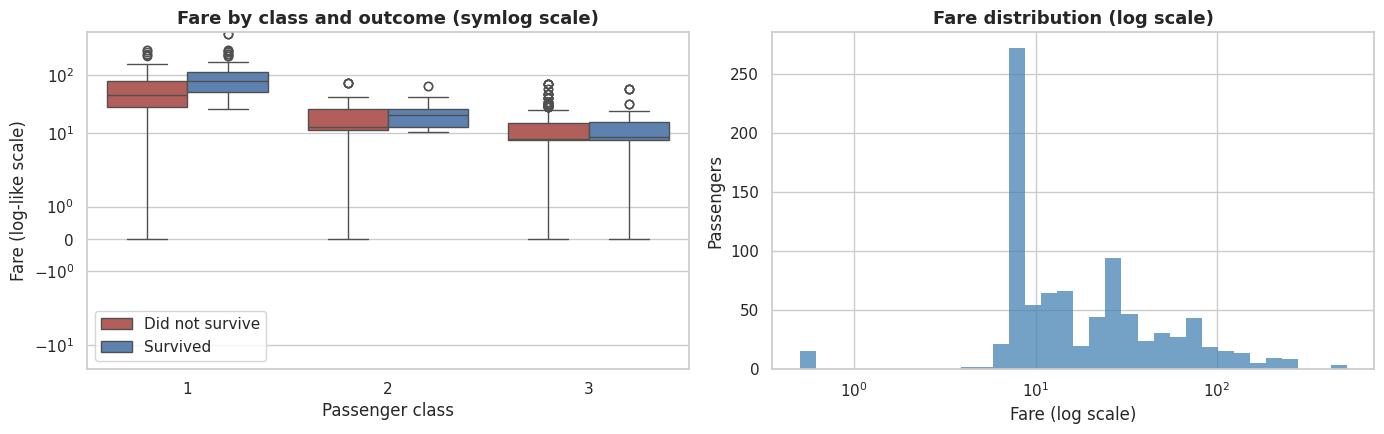

Fare summary by class:


,count,mean,50%,min,max
Pclass,,,,,
1,216.00,84.15,60.29,0.00,512.33
2,184.00,20.66,14.25,0.00,73.50
3,491.00,13.68,8.05,0.00,69.55


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="Pclass", y="Fare", hue="Survived", palette=PALETTE, ax=axes[0])
axes[0].set(yscale="symlog", title="Fare by class and outcome (symlog scale)", xlabel="Passenger class", ylabel="Fare (log-like scale)")
handles, _ = axes[0].get_legend_handles_labels(); axes[0].legend(handles, [SURV_LABELS[0], SURV_LABELS[1]], title="")

sns.histplot(df["Fare"].clip(lower=0.5), bins=np.logspace(np.log10(0.5), np.log10(520), 35), color="steelblue", ax=axes[1])
axes[1].set(xscale="log", title="Fare distribution (log scale)", xlabel="Fare (log scale)", ylabel="Passengers")
plt.tight_layout(); plt.show()

print("Fare summary by class:"); display(df.groupby("Pclass")["Fare"].describe()[["count", "mean", "50%", "min", "max"]])

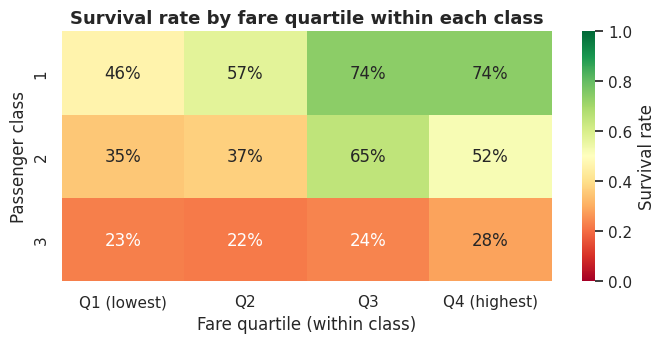

,Fare,FarePerPerson
Pclass,,
1,60.29,35.25
2,14.25,13.00
3,8.05,7.85


In [14]:
# Fare quartile WITHIN class vs survival
df["FareQuartileInClass"] = df.groupby("Pclass")["Fare"].transform(lambda s: pd.qcut(s.rank(method="first"), 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]))
fq = survival_table(df, ["Pclass", "FareQuartileInClass"])["survival_rate"].unstack("FareQuartileInClass")
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(fq, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "Survival rate"}, ax=ax)
ax.set(title="Survival rate by fare quartile within each class", xlabel="Fare quartile (within class)", ylabel="Passenger class")
plt.tight_layout(); plt.show()

# Does the class ordering hold if fare is divided among ticket-sharers?
display(df.groupby("Pclass")[["Fare", "FarePerPerson"]].median())

**What the data shows:** median fares are 60.3 (1st), 14.3 (2nd) and 8.05 (3rd); the fare distribution is heavily skewed with a maximum of 512. Survivors paid a higher median fare than non-survivors (26.0 vs 10.5, p < 1e-20), but that is largely because first-class passengers paid more.

Within class, survival rises with fare in **first class** (46% in the lowest fare quartile to 74% in the top two) and, less smoothly, in **second class** (35% to 52%, peaking at 65% in the third quartile). In **third class** it is flat (22-28% across quartiles).

**Interpretation:** fare carries some extra information beyond class for the upper classes, but none for third class. Fare is also linked to cabin location, group size and sex mix, so it should not be read as "paying more caused survival". Dividing fares among ticket-sharers leaves the class ordering unchanged (median 35.3, 13.0, 7.9).

### Q6. How does the average fare vary by port and class? (original brief)

Pclass,1,2,3
Embarked,,,
C,104.72,25.36,11.21
Q,90.00,12.35,11.18
S,70.51,20.33,14.64


As a nested dict (the format asked for in the original brief):
{'C': {1: 104.72, 2: 25.36, 3: 11.21}, 'Q': {1: 90.0, 2: 12.35, 3: 11.18}, 'S': {1: 70.51, 2: 20.33, 3: 14.64}}


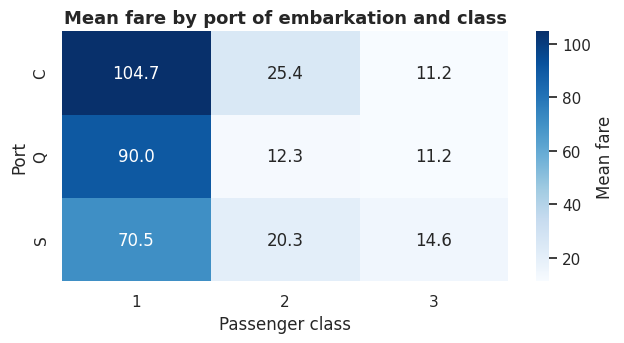

In [15]:
fare_table = df.groupby(["Embarked", "Pclass"])["Fare"].mean().round(2).unstack("Pclass")
display(fare_table)
print("As a nested dict (the format asked for in the original brief):")
print(fare_table.to_dict(orient="index"))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(fare_table, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Mean fare"}, ax=ax)
ax.set(title="Mean fare by port of embarkation and class", xlabel="Passenger class", ylabel="Port")
plt.tight_layout(); plt.show()

**What the data shows:** first-class passengers who boarded at **Cherbourg paid the most on average (104.7)**, versus 70.5 at Southampton; the three fares above 500 are all Cherbourg first-class tickets. The Queenstown first-class figure (90.0) rests on only 2 passengers. In third class, fares are similar at Cherbourg and Queenstown (about 11.2) and slightly higher at Southampton (14.6).

**Interpretation:** the port differences in first-class averages are driven partly by a handful of very expensive tickets, so medians would be more robust (first-class median: 78.3 at C vs 52.0 at S). The data does not indicate why.

## 9. Family
### Q7. Was travelling alone, or in a large family, related to survival?

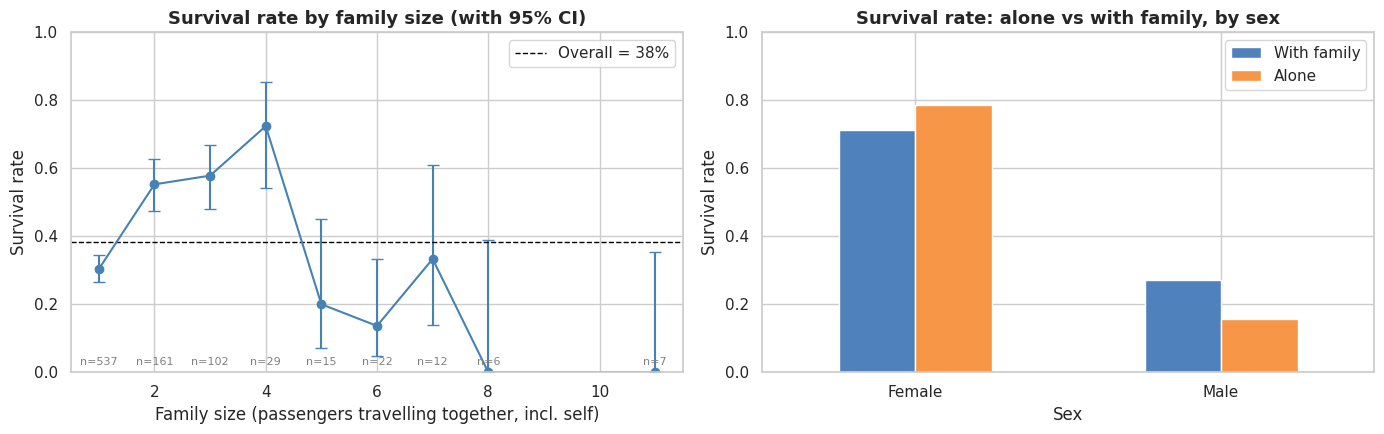

Pclass,1,2,3
FamilyBand,,,
Alone,0.53,0.35,0.21
2-4,0.73,0.63,0.41
5+,0.67,1.00,0.07


Pclass,1,2,3
FamilyBand,,,
Alone,109,104,324
2-4,101,78,113
5+,6,2,54


In [16]:
fam = survival_table(df, "FamilySize")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].errorbar(fam.index, fam["survival_rate"], yerr=[fam["survival_rate"] - fam["ci_low"], fam["ci_high"] - fam["survival_rate"]],
                 marker="o", capsize=4, color="steelblue")
axes[0].axhline(overall, color="black", ls="--", lw=1, label=f"Overall = {overall:.0%}")
for x, n in zip(fam.index, fam["passengers"]):
    axes[0].annotate(f"n={n}", (x, 0.02), ha="center", fontsize=8, color="gray")
axes[0].set(title="Survival rate by family size (with 95% CI)", xlabel="Family size (passengers travelling together, incl. self)", ylabel="Survival rate", ylim=(0, 1))
axes[0].legend()

alone = survival_table(df, ["Sex", "IsAlone"])["survival_rate"].unstack("IsAlone").rename(columns={0: "With family", 1: "Alone"})
alone.plot(kind="bar", ax=axes[1], color=["#4f81bd", "#f79646"], rot=0)
axes[1].set(title="Survival rate: alone vs with family, by sex", xlabel="Sex", ylabel="Survival rate", ylim=(0, 1))
axes[1].legend(title="")
plt.tight_layout(); plt.show()

fam_class = survival_table(df.assign(FamilyBand=pd.cut(df["FamilySize"], [0, 1, 4, 20], labels=["Alone", "2-4", "5+"])), ["FamilyBand", "Pclass"])
display(fam_class["survival_rate"].unstack("Pclass").round(3))
display(fam_class["passengers"].unstack("Pclass"))

**What the data shows:** survival is **not monotonic in family size**: passengers travelling alone survived at 30% (n=537), those in groups of 2-4 at 58% (n=292), and those in groups of 5 or more at only 16% (n=62).

Being alone is entangled with sex: 77% of solo travellers were men. Within each sex, alone women survived slightly more than women with family (79% vs 71%), while alone men survived less (16% vs 27%). By class, third-class large families did worst (7% survival, n=54); first- and second-class groups of 5+ are too small (n=6 and n=2) to judge.

**Interpretation:** the "large family" penalty in this data is mostly a third-class phenomenon. The dataset does not record where families were located on the ship or how they were separated, so the mechanism cannot be established.

## 10. Port and Cabin
### Q8. Is the port effect real, or a class effect in disguise?

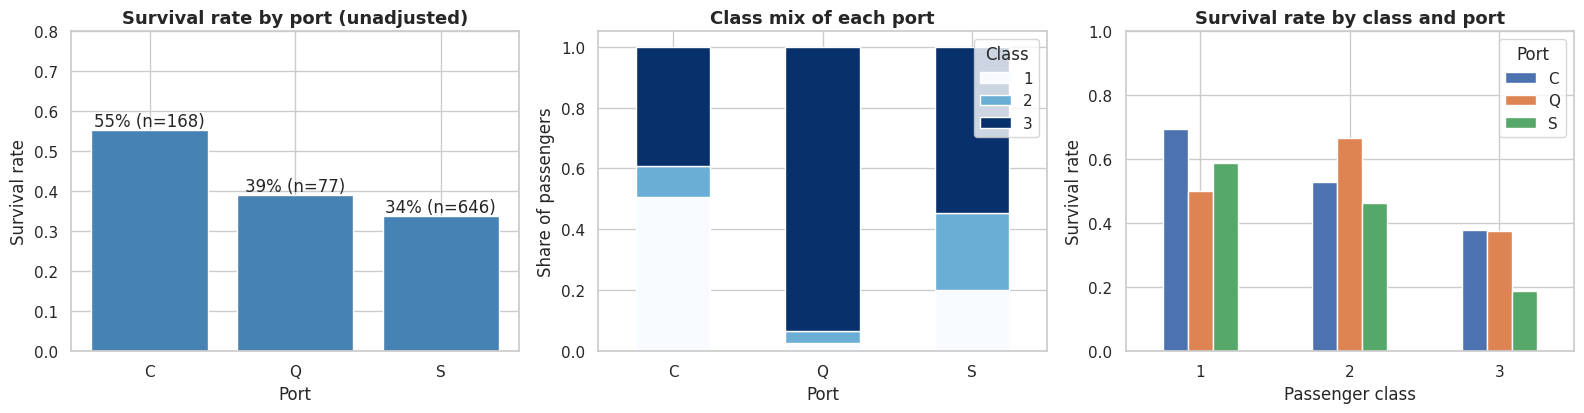

survivors  passengers  survival_rate  ci_low  ci_high
Pclass Embarked                                                       
1      C                59          85           0.69    0.59     0.78
       Q                 1           2           0.50    0.10     0.91
       S                76         129           0.59    0.50     0.67
2      C                 9          17           0.53    0.31     0.74
       Q                 2           3           0.67    0.21     0.94
       S                76         164           0.46    0.39     0.54
3      C                25          66           0.38    0.27     0.50
       Q                27          72           0.38    0.27     0.49
       S                67         353           0.19    0.15     0.23

In [17]:
port_raw = survival_table(df, "Embarked")
port_class = survival_table(df, ["Pclass", "Embarked"])
composition = pd.crosstab(df["Embarked"], df["Pclass"], normalize="index")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].bar(port_raw.index, port_raw["survival_rate"], color="steelblue")
for i, (r, n) in enumerate(zip(port_raw["survival_rate"], port_raw["passengers"])):
    axes[0].text(i, r + 0.01, f"{r:.0%} (n={n})", ha="center")
axes[0].set(title="Survival rate by port (unadjusted)", xlabel="Port", ylabel="Survival rate", ylim=(0, 0.8))
composition.plot(kind="bar", stacked=True, ax=axes[1], rot=0, colormap="Blues")
axes[1].set(title="Class mix of each port", xlabel="Port", ylabel="Share of passengers"); axes[1].legend(title="Class")
port_class["survival_rate"].unstack("Embarked").plot(kind="bar", ax=axes[2], rot=0)
axes[2].set(title="Survival rate by class and port", xlabel="Passenger class", ylabel="Survival rate", ylim=(0, 1)); axes[2].legend(title="Port")
plt.tight_layout(); plt.show()
display(port_class.round(3))

**What the data shows:** unadjusted survival is highest for **Cherbourg (55%, n=168)**, then Queenstown (39%, n=77) and Southampton (34%, n=644). But the ports have very different passenger mixes: **51% of Cherbourg passengers were first class**, 94% of Queenstown's were third class, and Southampton was mostly third class (55%).

Within class the gap mostly closes for first and second class (first class: 69% C vs 59% S; second class: 53% vs 46%, both with overlapping intervals). Third class is the exception: **Southampton 19%** (n=353) versus 38% at both Cherbourg and Queenstown. Part of this is composition (75% of third-class Southampton passengers were men vs 59% at C/Q), but third-class women also fared worse from Southampton (38%, n=88) than from Cherbourg (65%, n=23) or Queenstown (73%, n=33).

**Interpretation:** most of the apparent port effect is a class effect. A residual difference remains in third class, but the data has no information on cabin location or boarding order that could explain it.

In [18]:
# Cabin information: who has a recorded cabin, and does it relate to survival once class is known?
cab = survival_table(df, ["Pclass", "HasCabin"])
display(pd.concat([cab["passengers"].unstack("HasCabin").add_prefix("has_cabin_"),
                   cab["survival_rate"].unstack("HasCabin").add_prefix("survival_")], axis=1).round(3))

HasCabin,has_cabin_0,has_cabin_1,survival_0,survival_1
Pclass,,,,
1,40,176,0.47,0.67
2,168,16,0.44,0.81
3,479,12,0.24,0.50


**What the data shows:** a recorded cabin is mainly a first-class attribute (81% of first class, 9% of second, 2% of third). Within each class, passengers with a recorded cabin survived more often (1st: 67% vs 47%; 2nd: 81% vs 44%; 3rd: 50% vs 24%), although the 2nd- and 3rd-class groups with a cabin are tiny (n=16 and n=12).

**Interpretation:** this is a caution, not a finding. One possible explanation is that cabin details were more likely to be recorded for survivors, which would make the missing values informative rather than random. The data cannot confirm this, so cabin is used only as a descriptive feature and not as a driver of survival.

## 11. Multivariate View
### Q9. Which factors remain associated with survival when considered together?
Group comparisons can hide overlap (e.g. class and fare, port and class). A logistic regression estimates each factor's association *holding the others constant*. Results are reported as **odds ratios** (values above 1 = higher odds of survival, below 1 = lower). The goal is interpretation, not prediction.

,odds_ratio,ci_low,ci_high,p_value
Male,0.06,0.04,0.09,0.00
LargeFamily,0.06,0.02,0.16,0.00
Class3,0.16,0.07,0.35,0.00
Class2,0.42,0.21,0.83,0.01
AgeYears10,0.78,0.65,0.94,0.01
Alone,1.09,0.71,1.67,0.68
PortC,1.30,0.80,2.11,0.29
PortQ,1.35,0.69,2.66,0.38
LogFarePerPerson,1.43,0.95,2.14,0.09
Child,6.81,2.71,17.09,0.00


Pseudo R-squared (McFadden): 0.374 | n = 891


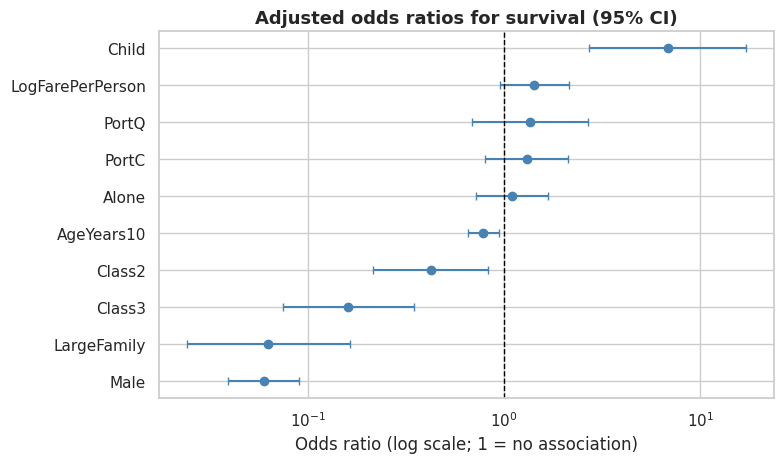

In [19]:
model_df = df.assign(
    Male=(df["Sex"] == "Male").astype(int),
    Class2=(df["Pclass"] == 2).astype(int),
    Class3=(df["Pclass"] == 3).astype(int),
    Child=(df["AgeFilled"] <= 12).astype(int),
    AgeYears10=df["AgeFilled"] / 10,
    LogFarePerPerson=np.log1p(df["FarePerPerson"]),
    Alone=df["IsAlone"],
    LargeFamily=(df["FamilySize"] >= 5).astype(int),
    PortC=(df["Embarked"] == "C").astype(int),
    PortQ=(df["Embarked"] == "Q").astype(int),
)
features = ["Male", "Class2", "Class3", "AgeYears10", "Child", "LogFarePerPerson", "Alone", "LargeFamily", "PortC", "PortQ"]
X = sm.add_constant(model_df[features].astype(float))
logit = sm.Logit(model_df["Survived"], X).fit(disp=0)

or_table = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(logit.conf_int()[0]),
                         "ci_high": np.exp(logit.conf_int()[1]), "p_value": logit.pvalues}).drop(index="const")
display(or_table.sort_values("odds_ratio").round(3))
print(f"Pseudo R-squared (McFadden): {logit.prsquared:.3f} | n = {int(logit.nobs)}")

fig, ax = plt.subplots(figsize=(8, 4.8))
o = or_table.sort_values("odds_ratio")
ax.errorbar(o["odds_ratio"], range(len(o)), xerr=[o["odds_ratio"] - o["ci_low"], o["ci_high"] - o["odds_ratio"]], fmt="o", color="steelblue", capsize=3)
ax.axvline(1, color="black", ls="--", lw=1)
ax.set(yticks=range(len(o)), yticklabels=o.index, xscale="log", title="Adjusted odds ratios for survival (95% CI)",
       xlabel="Odds ratio (log scale; 1 = no association)", ylabel="")
plt.tight_layout(); plt.show()

**What the data shows:** holding the other variables constant (McFadden pseudo-R² = 0.37):
- **Male:** odds of survival about 94% lower (odds ratio 0.06, 95% CI 0.04-0.09).
- **Class:** third class 0.16 and second class 0.42 relative to first class.
- **Family of 5 or more:** odds ratio 0.06 (0.02-0.16).
- **Age:** each extra 10 years lowers the odds (0.78, 0.65-0.94), and being a child (12 or under) has a separate large positive association (6.8, 2.7-17.1).
- **Not clearly associated once the above are included:** travelling alone (1.09, p = 0.68), port of embarkation (Cherbourg 1.30, Queenstown 1.35, both p > 0.25) and fare per person (1.43, p = 0.09).

**Interpretation:** sex, class, large family size and age keep their association after adjustment, whereas the port and "alone" effects seen earlier largely disappear, in line with the confounding checks above. Caveats: the model has no interaction terms, although the sex × class interaction is clear in the heatmap; the child indicator relies partly on imputed ages; and class and fare are correlated (Spearman -0.69), so the fare estimate is unstable.

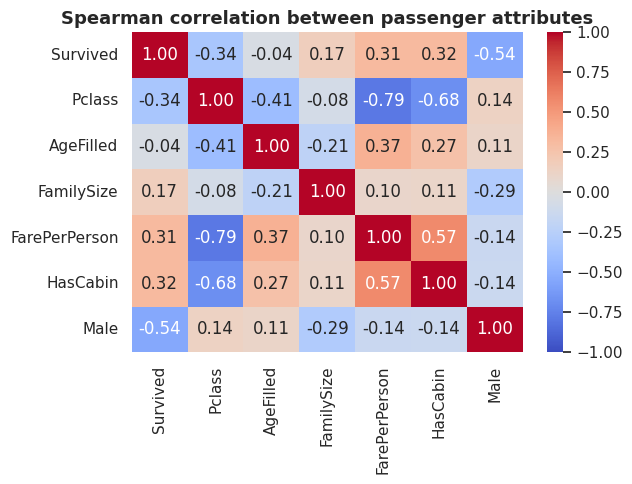

In [20]:
# Correlation overview of numeric features (Spearman, robust to skew)
num = df[["Survived", "Pclass", "AgeFilled", "FamilySize", "FarePerPerson", "HasCabin"]].assign(Male=(df["Sex"] == "Male").astype(int))
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set(title="Spearman correlation between passenger attributes")
plt.tight_layout(); plt.show()

## 12. Key Findings


1. **Sex and class dominate.** 74% of women survived versus 19% of men, and survival fell from 63% (1st) to 47% (2nd) to 24% (3rd). Together they interact strongly: 97% of first-class women survived versus 14% of third-class men.
2. **Class mattered more for women than for men.** Third-class women (50%) lost most of the advantage that first- and second-class women had (92-97%), whereas among men only first class stood out (37% vs 14-16%).
3. **Children were favoured.** Children aged 12 or under survived at 58% (boys and girls alike), but this varied by class (100% in 2nd class, 42% in 3rd).
4. **Family size has a non-linear relationship.** Groups of 2-4 survived best (58%), solo travellers 30% and groups of 5 or more only 16%, the latter driven by third-class families.
5. **The port effect is mostly a class effect.** Cherbourg's high survival reflects its first-class-heavy passenger mix. A residual gap remains only in third class (Southampton 19% vs 38%).
6. **Fare adds information only in the upper classes.** Survival rises with fare within first class but is flat in third class.
7. **Data quality shapes the analysis.** Age is missing more often for third-class passengers (28%), so dropping those rows would bias results; cabin availability is itself a class marker and possibly a survivor-recording artefact.
8. **Adjusted view:** in a logistic regression, sex, class, age and large family size remain associated with survival; port and travelling alone do not.

## 13. Limitations & Next Steps
- **Association, not causation.** The data cannot say *why* groups differed; social norms, cabin location and lifeboat access are not recorded.
- **Sample:** 891 of the passengers aboard (the Kaggle training split), so group sizes are small in places; confidence intervals are shown for that reason.
- **Imputation:** `AgeFilled` is an estimate (used only in the regression). Age-specific charts use recorded ages, which cover 80% of passengers; missing ages are more common in 3rd class.
- **Fare ambiguity:** fares repeat across passengers on one ticket; `FarePerPerson` is a reasonable adjustment but not confirmed by the data.
- **Next steps:** cross-validated predictive model, using the held-out test file, and analysis of surname/family groups.